Data in `(Space x Time)` => (16384, 1001)

In [1]:
import numpy as np
from scipy.ndimage import correlate
from csaps import csaps


def grad1(in1, h):
    """
    4th-order central-difference gradient along axis 1 (columns/last axis),
    direct translation of grad1.m.

    Parameters
    ----------
    in1 : ndarray, shape (noy1, nox1)
    h : float
        Spatial step.

    Returns
    -------
    out1 : ndarray, shape (noy1, nox1)
    """
    in1 = np.asarray(in1, dtype=float)
    noy1, nox1 = in1.shape # 1001, 16384
    noxz = nox1 + 4 # 16389

    inp = np.zeros((noy1, noxz))
    # MATLAB: in(:,1)=in1(:,nox1-1); in(:,2)=in1(:,nox1);
    inp[:, 0] = in1[:, nox1 - 2]
    inp[:, 1] = in1[:, nox1 - 1]
    # MATLAB: in(:,3:nox1+2)=in1;
    inp[:, 2:nox1 + 2] = in1
    # MATLAB: in(:,noxz-1)=in(:,2); in(:,noxz)=in(:,1);
    inp[:, noxz - 2] = in1[:, 1]
    inp[:, noxz - 1] = in1[:, 0]

    out = np.zeros((noy1, noxz))
    # MATLAB: out(:,3:noxz-2) = (-in(:,1:noxz-4)+8*in(:,2:noxz-3)
    #                            -8*in(:,4:noxz-1)+in(:,5:noxz)) / (12*h)
    out[:, 2:noxz - 2] = (
        -inp[:, 0:noxz - 4]
        + 8 * inp[:, 1:noxz - 3]
        - 8 * inp[:, 3:noxz - 1]
        + inp[:, 4:noxz]
    ) / (12 * h)

    out1 = out[:, 2:nox1 + 2]
    return out1


def _fspecial_gaussian(shape, sigma):
    """Reproduce MATLAB's fspecial('gaussian', shape, sigma)."""
    m, n = shape
    siz_y = (m - 1) / 2
    siz_x = (n - 1) / 2
    y, x = np.meshgrid(
        np.arange(-siz_y, siz_y + 1),
        np.arange(-siz_x, siz_x + 1),
        indexing="ij",
    )
    arg = -(x ** 2 + y ** 2) / (2 * sigma ** 2)
    h = np.exp(arg)
    h[h < np.finfo(float).eps * h.max()] = 0
    s = h.sum()
    if s != 0:
        h = h / s
    return h


def grad1_smooth(in1, h):
    """
    grad1 followed by a Gaussian-smoothed (near-box, since sigma=1e6)
    8x8 filter with replicate boundary handling, translation of
    grad1_smooth.m.
    """
    sigma = 1_000_000
    gaussian_kernel = _fspecial_gaussian((8, 8), sigma)

    out1 = grad1(in1, h)
    # MATLAB imfilter(..., 'replicate') -> scipy 'nearest' boundary mode
    out1 = correlate(out1, gaussian_kernel, mode="nearest")
    return out1


def spline_smooth_5(ux, t, x, p=0.995):
    """
    Cubic smoothing-spline denoising: smooth along x, then along t, then
    along x again, translation of spline_smooth_5.m.

    Parameters
    ----------
    ux : ndarray, shape (nx, nt)
        Rows correspond to the spatial grid `x`, columns to the time
        grid `t` (matching the convention used throughout the MATLAB
        script, e.g. sfr3.eta).
    t : 1D array, length nt
    x : 1D array, length nx
    p : float
        Smoothing parameter (MATLAB used .995 throughout).

    Returns
    -------
    ndarray, shape (nx, nt)
    """
    ux = np.asarray(ux, dtype=float)

    # csaps(x, ux.', p, x).'  -> smooth along x for every time slice
    ux = csaps(x, ux.T, x, smooth=p).T
    # csaps(t, ux, p, t)      -> smooth along t for every spatial point
    ux = csaps(t, ux, t, smooth=p)
    # csaps(x, ux.', p, x).'  -> smooth along x again
    ux = csaps(x, ux.T, x, smooth=p).T

    return ux

In [2]:
import os
from datetime import datetime
 
import numpy as np
from scipy.io import savemat
from scipy.signal import hilbert
from pymatreader import read_mat

In [3]:
# fpath = r"data\test_MXBKBW_0d222_1d337_1d248_bak_surf1_pert.mat"
fpath = r"data\test_BK_0d224_1d073_bak_surf1_pert.mat"

data = read_mat(fpath)
sfr3 = data["sfr3"]
time_vec = np.asarray(data["time_vec"]).ravel()
x1 = np.asarray(data["x1"]).ravel()
time_len_min = int(data["time_len_min"])

for key in list(sfr3.keys()):
    sfr3[key] = np.asarray(sfr3[key])[:, :time_len_min]

time_vec = time_vec[:time_len_min]
t = time_vec
x = x1
dx = x[1] - x[0]
dt = t[1] - t[0]


In [4]:
sfr3.keys()

dict_keys(['ux', 'uy', 'dud_y', 'dud_x', 'dudt_T_y', 'dudt_T_x', 'dwd_x', 'p', 'eta', 'dwd_y'])

In [5]:
sfr3['dud_x'].shape

(16384, 1001)

In [6]:
uy, ux = sfr3["uy"], sfr3["ux"]
eta_smooth = spline_smooth_5(sfr3["eta"], t, x)
ux_smooth = spline_smooth_5(sfr3["ux"], t, x)
uy_smooth = spline_smooth_5(sfr3["uy"], t, x)

In [7]:
eta = sfr3["eta"]
eta.shape, eta_smooth.shape

((16384, 1001), (16384, 1001))

In [8]:
eta[0], eta[:,0]
print("Across Time")
print(eta[0].shape, eta_smooth[:,0])
print("-"*50,"\nAcross Space")
print(eta[:,0].shape, eta_smooth[:,0])

Across Time
(1001,) [2.43457648e-04 2.45447237e-04 2.47435558e-04 ... 8.32970814e-05
 8.53204538e-05 8.73450679e-05]
-------------------------------------------------- 
Across Space
(16384,) [2.43457648e-04 2.45447237e-04 2.47435558e-04 ... 8.32970814e-05
 8.53204538e-05 8.73450679e-05]


In [9]:
import matplotlib.pyplot as plt
import numpy as np

def dataset_verif_plot(arr, arr_smooth, param_name, label1="Raw", label2="Spline Smoothed"):
    uy_flat = arr.squeeze()
    uy_smooth_flat = arr_smooth.squeeze()
    difference = uy_flat - uy_smooth_flat

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    ax1.plot(uy_flat, label=f'{label1} {param_name}', color='black', alpha=0.8, linewidth=1.5)
    ax1.plot(uy_smooth_flat, label=f'{label2} {param_name}', color='crimson', linewidth=1)
    ax1.set_title(f'{param_name} Comparison')
    ax1.set_ylabel(f'{param_name}')
    ax1.legend(loc='upper right')
    ax1.grid(True, linestyle='--', alpha=0.5)


    ax2.plot(difference, color='darkblue', linewidth=1, label='Difference (Noise/Residuals)')
    ax2.axhline(0, color='black', linestyle='-', alpha=0.3)  # Zero baseline
    ax2.set_title(f'Extracted Residuals')
    if len(uy_flat) >1001: 
        ax2.set_xlabel('Spatial Grid Index')
    else:
        ax2.set_xlabel('Temporal Grid Index')
    ax2.set_ylabel('Difference Magnitude')
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()


In [10]:
deta_dt = -grad1(sfr3["eta"], time_vec[1] - time_vec[0])
deta_dt_smooth = spline_smooth_5(deta_dt, t, x)
deta_dx = -grad1(sfr3["eta"].T, x[1] - x[0]).T
deta_dx_smooth = spline_smooth_5(deta_dx, t, x)

In [11]:
dud_x = sfr3["dud_x"]
ux = np.squeeze(sfr3["ux"])
# dudx = -grad1_smooth(ux.T, x[1] - x[0]).T
dudx = -grad1(ux.T, dx).T
dudx_smooth = spline_smooth_5(dudx, t, x)

In [12]:
dud_x[:, 0], dudx[:, 0], dudx_smooth[:, 0]

(array([ 0.4678314,  0.1849504, -0.188404 , ..., -0.1802858,  0.1815174,
         0.466308 ], shape=(16384,)),
 array([ 0.04137478,  0.09125684,  0.06177187, ..., -0.07565591,
        -0.10156089,  0.02437201], shape=(16384,)),
 array([ 0.03218169,  0.03071681,  0.02925283, ..., -0.02410901,
        -0.02529644, -0.02648455], shape=(16384,)))

In [13]:
import numpy as np

def grad_4th_order_axis1(in1, h, periodic=True):
    arr = np.asarray(in1, dtype=float)
    
    pad_mode = 'wrap' if periodic else 'edge'
    inp = np.pad(arr, ((0, 0), (2, 2)), mode=pad_mode)
    
    out = (
        - inp[:, 4:]        # f(x + 2h)
        + 8 * inp[:, 3:-1]  # f(x + h)
        - 8 * inp[:, 1:-3]  # f(x - h)
        + inp[:, :-4]       # f(x - 2h)
    ) / (12 * h)
    
    return out


In [14]:
import numpy as np

def grad_4th_order_non_periodic(in1, h):
    """
    Computes a 4th-order accurate gradient along Axis 1 (columns)
    using asymmetrical one-sided 4th-order stencils at the boundaries.
    
    Parameters:
    -----------
    in1 : ndarray, shape (M, N) -> your data slice
    h   : float -> spatial step (dx) or time step (dt)
    """
    f = np.asarray(in1, dtype=float)
    M, N = f.shape
    
    # Pre-allocate output matrix
    out = np.zeros_like(f)
    
    # 1. COMPUTE THE INTERIOR POINTS (Using standard central differences)
    # This covers all indices from 2 up to N-3
    out[:, 2:-2] = (
        - f[:, 4:]        # f(x + 2h)
        + 8 * f[:, 3:-1]  # f(x + h)
        - 8 * f[:, 1:-3]  # f(x - h)
        + f[:, :-4]       # f(x - 2h)
    ) / (12 * h)
    
    # 2. LEFT BOUNDARY CONDITIONS (One-sided Forward Stencils)
    # Index 0
    out[:, 0] = (-25*f[:, 0] + 48*f[:, 1] - 36*f[:, 2] + 16*f[:, 3] - 3*f[:, 4]) / (12 * h)
    # Index 1
    out[:, 1] = ( -3*f[:, 0] - 10*f[:, 1] + 18*f[:, 2] -  6*f[:, 3] +   f[:, 4]) / (12 * h)
    
    # 3. RIGHT BOUNDARY CONDITIONS (One-sided Backward Stencils)
    # Index N-2
    out[:, -2] = (-f[:, -5] + 6*f[:, -4] - 18*f[:, -3] + 10*f[:, -2] + 3*f[:, -1]) / (12 * h)
    # Index N-1
    out[:, -1] = (3*f[:, -5] - 16*f[:, -4] + 36*f[:, -3] - 48*f[:, -2] + 25*f[:, -1]) / (12 * h)
    
    return out


In [15]:
detadt = grad_4th_order_axis1(eta, dx)
detadt_nonperiod = grad_4th_order_non_periodic(eta, dx)

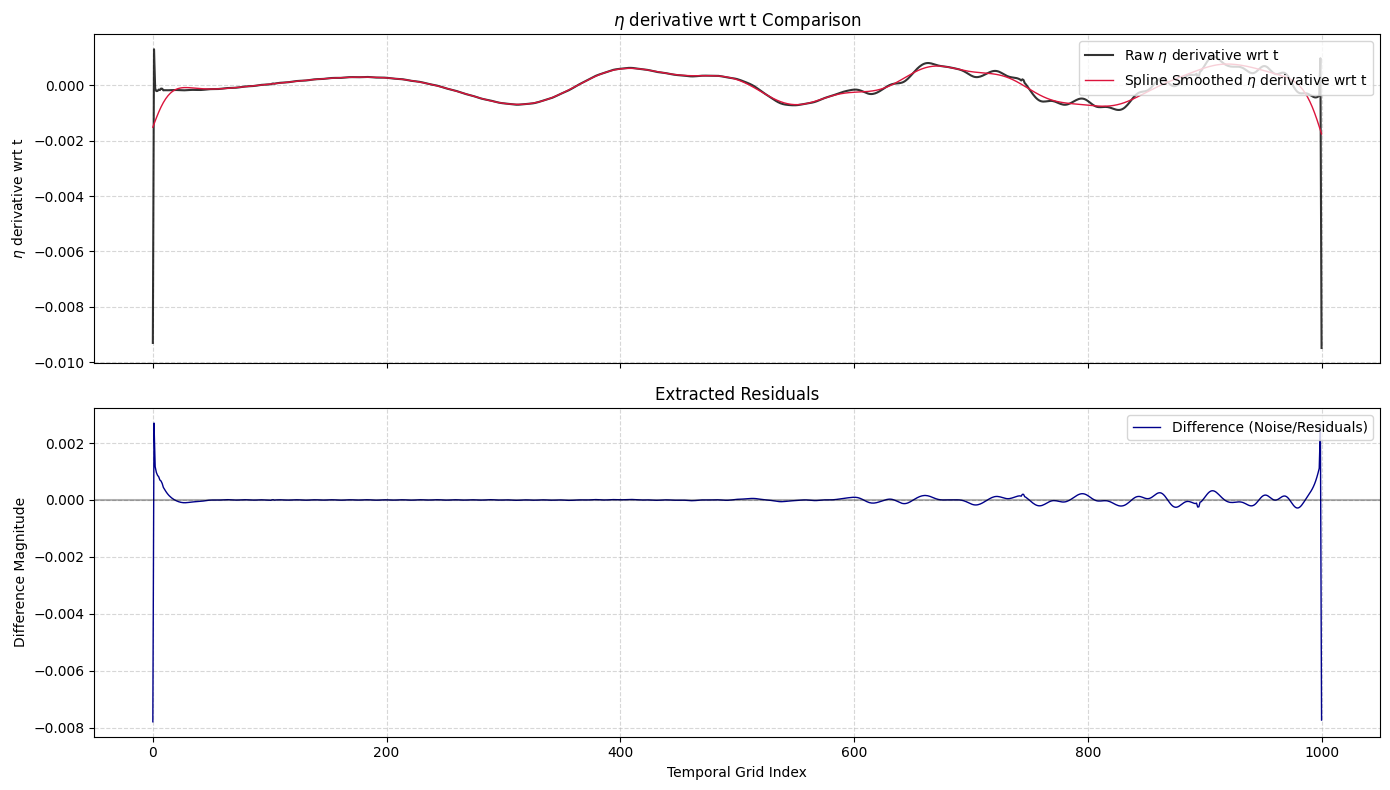

In [16]:
dataset_verif_plot(deta_dt[456], deta_dt_smooth[456], param_name=r"$\eta$ derivative wrt t")

In [17]:
field = np.asarray(eta)
label = "eta"
left_val = field[0, :]
right_val = field[-1, :]
diff = np.abs(left_val - right_val)
rel = diff / (np.abs(left_val) + np.abs(right_val) + 1e-12)

In [18]:
print(
        f"[{label}] mean|left-right| = {diff.mean():.4g}, "
        f"mean relative diff = {rel.mean():.4g} "
        f"(near 0 supports periodicity; large values suggest it's not periodic)"
    )

[eta] mean|left-right| = 1.354e-07, mean relative diff = 0.001389 (near 0 supports periodicity; large values suggest it's not periodic)


In [19]:
def spline_smooth(ux, t, x, p=0.995, p_x=None, p_t=None, passes="xtx"):
   
    ux = np.asarray(ux, dtype=float)
    px = p_x if p_x is not None else p
    pt = p_t if p_t is not None else p
 
    for axis in passes:
        if axis == "x":
            ux = csaps(x, ux.T, x, smooth=px).T
        elif axis == "t":
            ux = csaps(t, ux, t, smooth=pt)
        else:
            raise ValueError("passes must only contain 'x' and/or 't'")
 
    return ux

def smoothing_amplitude_ratio(raw, smoothed):

    raw = np.asarray(raw)
    smoothed = np.asarray(smoothed)
    raw_amp = raw.max(axis=1) - raw.min(axis=1)
    smooth_amp = smoothed.max(axis=1) - smoothed.min(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(raw_amp > 0, smooth_amp / raw_amp, np.nan)
    return ratio


In [20]:
smoothing_amplitude_ratio(eta.T, eta_smooth.T)

array([1.14608461, 1.1115517 , 1.06675474, ..., 0.94376221, 0.97271997,
       1.01604158], shape=(1001,))

In [21]:
for passes, p_x, p_t in [
    ("xtx", 0.995, 0.995),   # original
    ("t",   None,  0.995),   # skip spatial smoothing entirely
    ("xt",  0.9999, 0.995),  # single, much lighter spatial pass
    ("xtx", 0.99999, 0.999), # both axes pushed much closer to interpolation
]:
    ux_smoothed = spline_smooth(sfr3["ux"], t, x, p_x=p_x, p_t=p_t, passes=passes)
    ratio = smoothing_amplitude_ratio(sfr3["ux"], ux_smoothed)
    print(passes, p_x, p_t, "-> amplitude ratio at row 6500:", ratio[6500])


xtx 0.995 0.995 -> amplitude ratio at row 6500: 1.031164122306943
t None 0.995 -> amplitude ratio at row 6500: 0.8912341086951644
xt 0.9999 0.995 -> amplitude ratio at row 6500: 0.8914110297992348
xtx 0.99999 0.999 -> amplitude ratio at row 6500: 0.9042492348914022


In [22]:
eta_smoothed = spline_smooth(eta, t, x, p_x=None, p_t=0.995, passes="t")

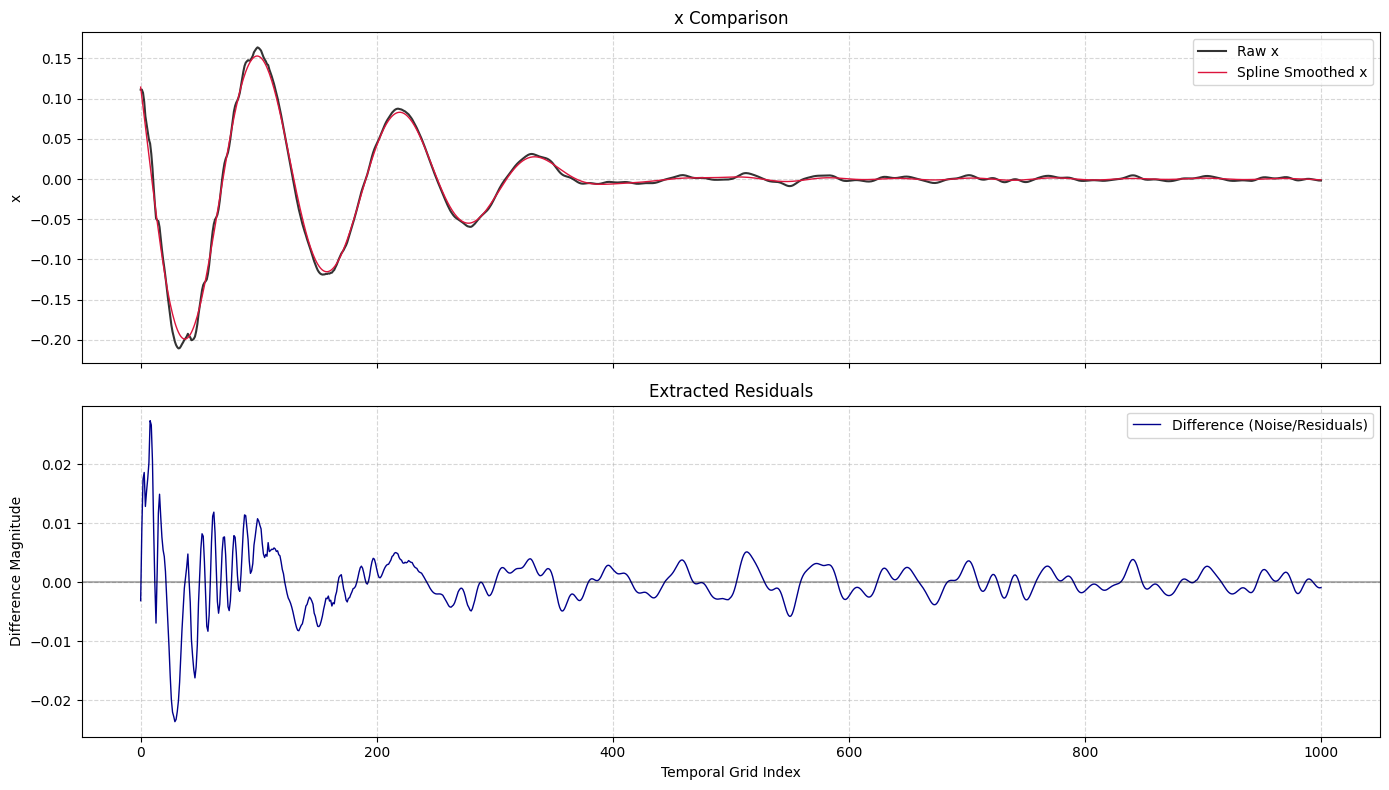

In [23]:
dataset_verif_plot(uy[6800], uy_smooth[6800], param_name="x")

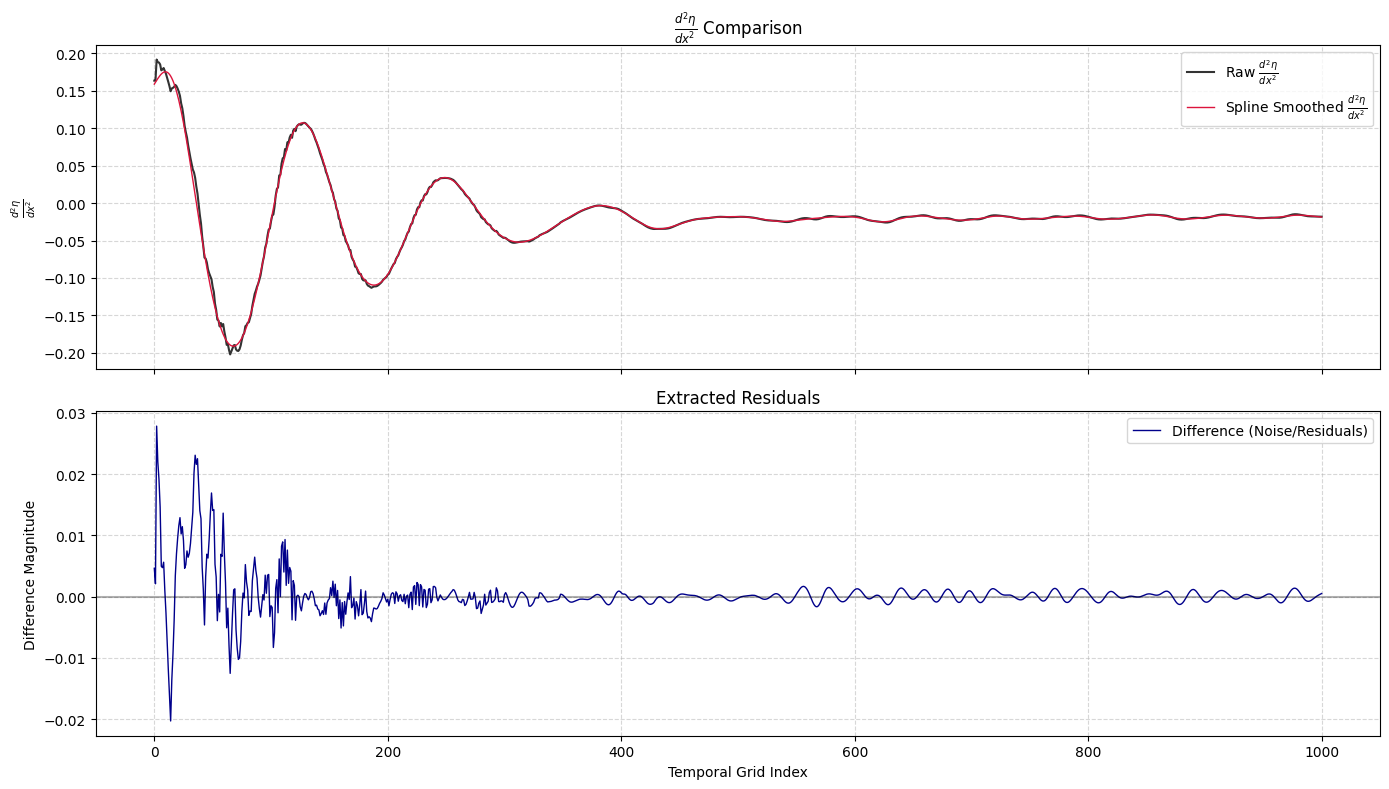

In [24]:
dataset_verif_plot(ux[6800], ux_smoothed[6800], param_name=r"$\frac{d^2\eta}{dx^2}$")

In [25]:
# du_dt = -grad1_smooth(ux, dt)
du_dt = -grad1(ux, dt)
du_dt_smooth = spline_smooth_5(du_dt, t, x)

In [26]:
# duydx = -grad1_smooth(uy.T, dx).T
duydx = -grad1(uy.T, dx).T
duydx_smooth = spline_smooth_5(duydx, t, x)

In [27]:
# deta_dx2 = -grad1_smooth(deta_dx.T, dx).T
deta_dx2 = -grad1(deta_dx.T, dx).T
deta_dx2_smooth = spline_smooth_5(deta_dx2, t, x)

In [28]:
deta_dx2_smoothed = spline_smooth(deta_dx2, t, x, p_x=0.9999, p_t=0.995)

In [29]:
du_dt_smoothed = spline_smooth(du_dt, t, x, p_x=0.9999, p_t=0.995)

In [30]:
deta_dx_smoothed = spline_smooth(deta_dx, t, x, p_x=0.9999)
dudx_smoothed = spline_smooth(dudx, t, x, p_x=0.9999)
duy_dx_smoothed = spline_smooth(duydx, t, x, p_x=0.9999)
uy_smoothed = spline_smooth(uy, t, x, p_x=0.9999)

In [31]:
from wave_breaking import build_case_dataset

wave_period = float(os.path.basename(fpath).split("_")[3].replace("d", "."))
case = build_case_dataset(sfr3, t, x, wave_period)
MSK = case["mask"]
deta_dx_smooth = case["deta_dx_smooth"]
du_dt_smooth = case["du_dt_smooth"]
RHS_smooth = case["rhs"]
result_smooth = case["residual_field"]

# Keep the downstream comparison cells runnable with the canonical calculation.
du_dt = du_dt_smooth
RHS = RHS_smooth
result = result_smooth


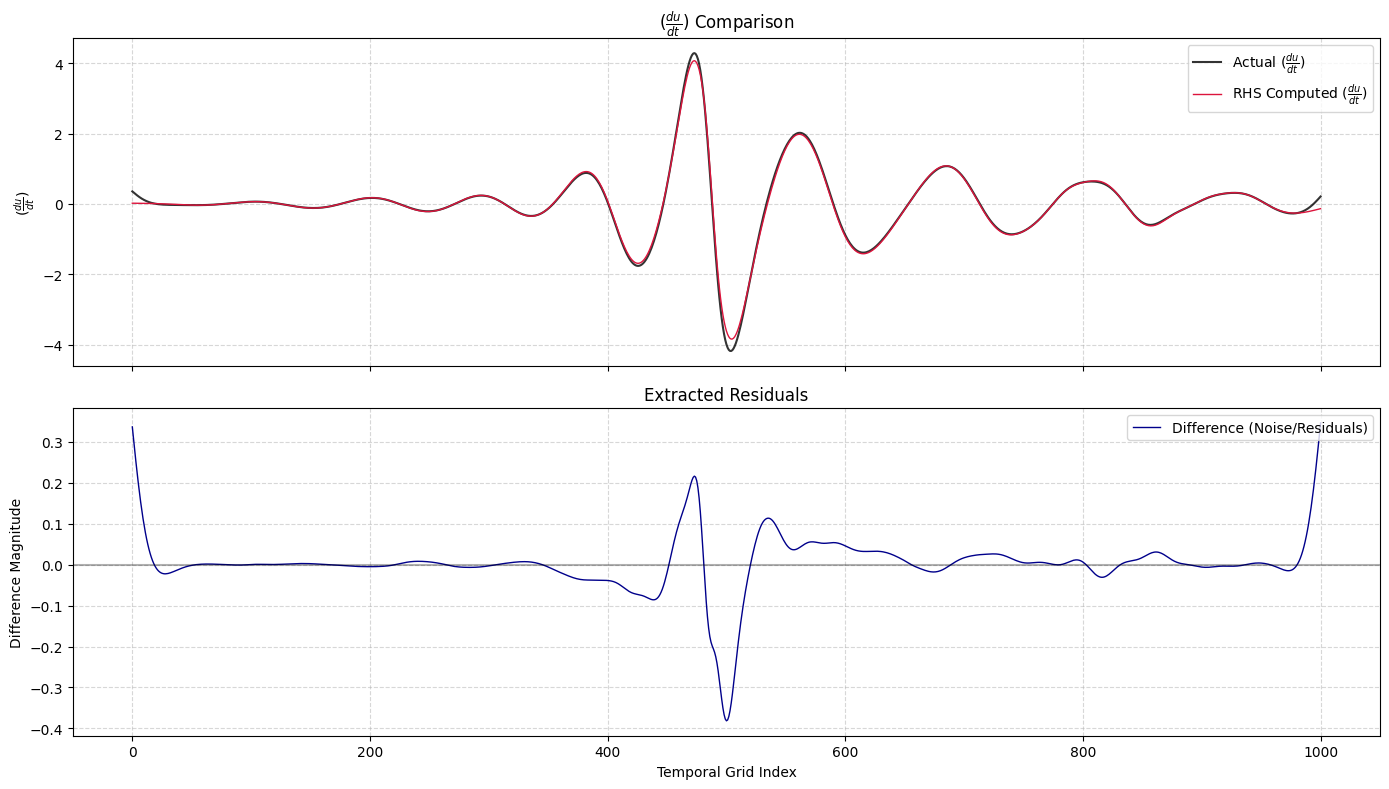

In [32]:
dataset_verif_plot(du_dt_smooth[7600], RHS_smooth[7600], param_name=r"$(\frac{du}{dt}$)",
                   label1="Actual", label2="RHS Computed")

In [33]:
MSK = case["mask"]


In [34]:
int(np.sum(MSK))

17537

In [35]:
eta_x_temp = deta_dx_smooth[MSK]
num_data_points = eta_x_temp.shape[0]

In [36]:
matrix = np.copy(MSK)

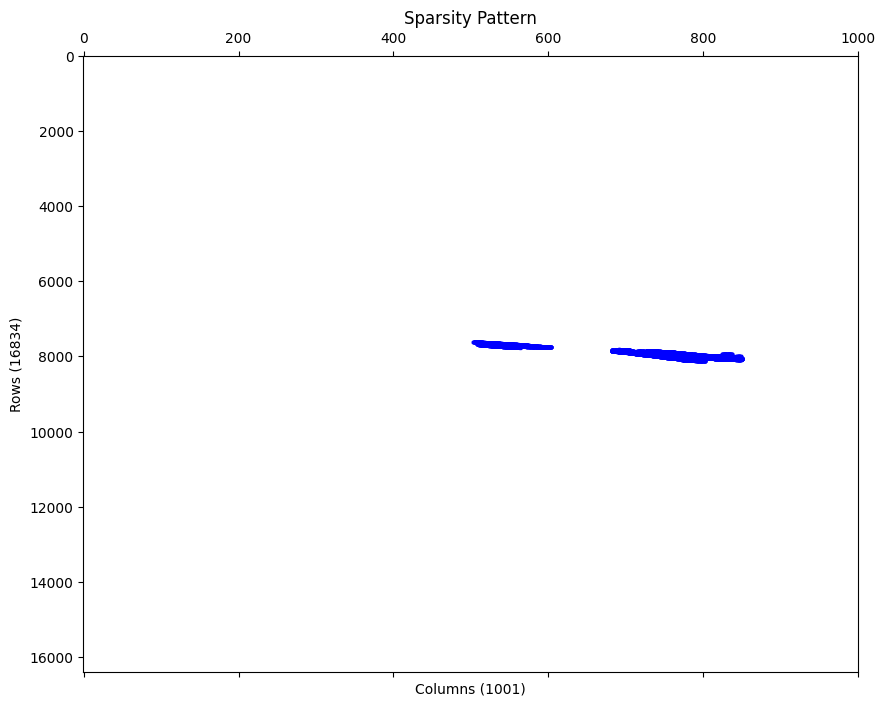

In [37]:
plt.figure(figsize=(10, 8))

# markersize controls how large the non-zero (True) points appear
plt.spy(matrix, aspect='auto', markersize=2, color='blue')

plt.title("Sparsity Pattern")
plt.xlabel("Columns (1001)")
plt.ylabel("Rows (16834)")
plt.show()

In [38]:
for passes, p_x, p_t in [
    ("xtx", 0.995, 0.995),   # original
    ("t",   None,  0.995),   # skip spatial smoothing entirely
    ("xt",  0.9999, 0.995),  # single, much lighter spatial pass
    ("xtx", 0.99999, 0.999), # both axes pushed much closer to interpolation
]:
    dudt_smoothed = spline_smooth(du_dt, t, x, p_x=p_x, p_t=p_t, passes=passes)
    ratio = smoothing_amplitude_ratio(du_dt, dudt_smoothed)
    print(passes, p_x, p_t, "-> amplitude ratio at row 6800:", ratio[7600])


xtx 0.995 0.995 -> amplitude ratio at row 6800: 0.7488141798797368
t None 0.995 -> amplitude ratio at row 6800: 0.8047469346018212
xt 0.9999 0.995 -> amplitude ratio at row 6800: 0.8041373016315302
xtx 0.99999 0.999 -> amplitude ratio at row 6800: 0.9422367316760383


In [41]:
int(np.sum(matrix))

17537